<a href="https://colab.research.google.com/github/AlbertPuentes/NLP_ACT_YouTube_III/blob/main/Act_Avance_YT_III.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/tmp/ipykernel_1132/2908925831.py:77: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  weighted_sent_series = df_c.groupby('Video ID').apply(weighted_sentiment).reset_index(name='weighted_sentiment')


=== RESULTADOS MODELO OPTIMIZADO ===
R² Score: 0.6480
MAE (Log Views): 1.0766
RMSE (Log Views): 1.4668
Exactitud (Accuracy): 82.09%
F1-Score: 0.8223

Reporte de Clasificación:
               precision    recall  f1-score   support

           0       0.78      0.87      0.82       175
           1       0.87      0.78      0.82       199

    accuracy                           0.82       374
   macro avg       0.82      0.82      0.82       374
weighted avg       0.83      0.82      0.82       374



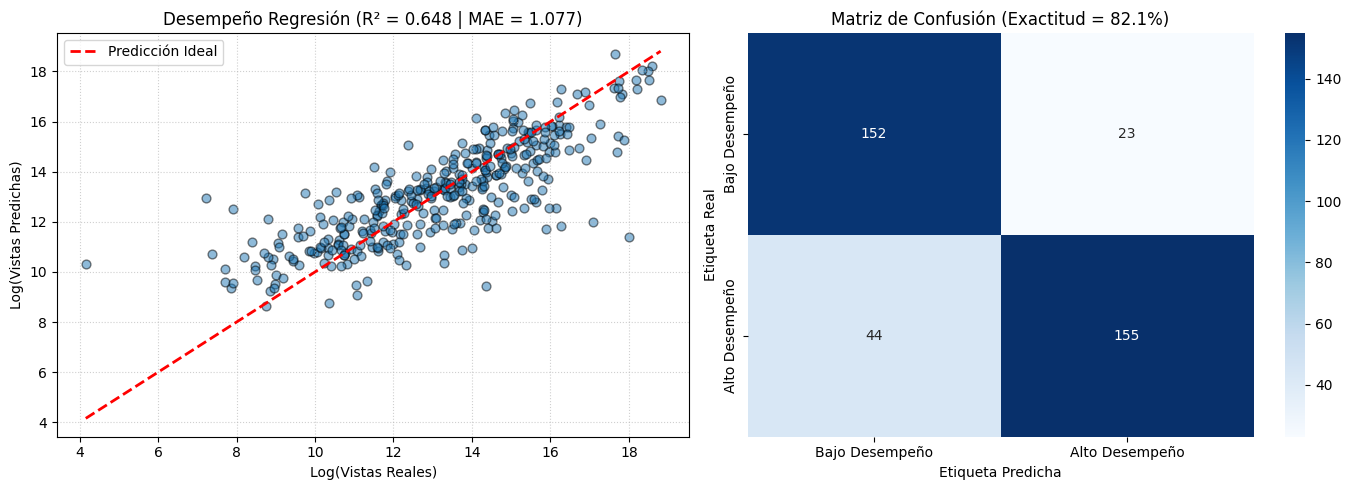

In [1]:
import re
import html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.ensemble import (
    HistGradientBoostingRegressor, HistGradientBoostingClassifier,
    RandomForestRegressor, RandomForestClassifier,
    VotingRegressor, VotingClassifier
)
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.metrics import (
    r2_score, mean_absolute_error, mean_squared_error,
    accuracy_score, f1_score, classification_report, confusion_matrix
)

# ==========================================
# 1. CARGA, DEDUPLICACIÓN Y LIMPIEZA
# ==========================================
videos_df = pd.read_csv('videos-stats.csv')
comments_df = pd.read_csv('comments.csv')

# Filtrar nulos y deduplicar por Video ID (evita Data Leakage)
videos_df = videos_df.dropna(subset=['Views', 'Video ID'])
videos_df = videos_df[videos_df['Views'] > 0]
videos_df = videos_df.sort_values('Views', ascending=False).drop_duplicates(subset=['Video ID']).reset_index(drop=True)

comments_df = comments_df.dropna(subset=['Comment', 'Video ID']).copy()
comments_df['Sentiment'] = comments_df['Sentiment'].fillna(1).astype(int)
comments_df['Likes'] = comments_df['Likes'].fillna(0)

# ==========================================
# 2. FEATURE ENGINEERING NLP Y DE ENGAGEMENT
# ==========================================
def clean_text(text: str) -> str:
    """Limpia entidades HTML, URLs y caracteres especiales."""
    text = html.unescape(str(text))
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'[^a-zA-Z0-9\s!?]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip().lower()
    return text

def extract_advanced_comment_features(df_comments: pd.DataFrame) -> pd.DataFrame:
    # Métricas a nivel de comentario individual
    df_c = df_comments.copy()
    df_c['char_len'] = df_c['Comment'].apply(lambda x: len(str(x)))
    df_c['word_count'] = df_c['Comment'].apply(lambda x: len(str(x).split()))
    df_c['has_question'] = df_c['Comment'].apply(lambda x: 1 if '?' in str(x) else 0)
    df_c['has_exclamation'] = df_c['Comment'].apply(lambda x: 1 if '!' in str(x) else 0)
    df_c['caps_ratio'] = df_c['Comment'].apply(
        lambda x: sum(1 for c in str(x) if c.isupper()) / (len(str(x)) + 1)
    )
    df_c['clean_comment'] = df_c['Comment'].apply(clean_text)

    # Agregación por Video ID
    grouped = df_c.groupby('Video ID')

    text_agg = grouped['clean_comment'].apply(lambda x: " ".join(x)).reset_index()
    text_agg.rename(columns={'clean_comment': 'all_comments_text'}, inplace=True)

    def weighted_sentiment(sub_df):
        likes = sub_df['Likes'].values
        sent = sub_df['Sentiment'].values
        total_likes = np.sum(likes)
        if total_likes > 0:
            return float(np.sum(sent * likes) / total_likes)
        return float(np.mean(sent))

    weighted_sent_series = df_c.groupby('Video ID').apply(weighted_sentiment).reset_index(name='weighted_sentiment')

    stats_agg = grouped.agg(
        num_comments_scraped=('Comment', 'count'),
        avg_comment_likes=('Likes', 'mean'),
        max_comment_likes=('Likes', 'max'),
        total_comment_likes=('Likes', 'sum'),
        mean_sentiment=('Sentiment', 'mean'),
        std_sentiment=('Sentiment', lambda x: x.std() if len(x) > 1 else 0),
        pct_neg=('Sentiment', lambda x: (x == 0).mean()),
        pct_neu=('Sentiment', lambda x: (x == 1).mean()),
        pct_pos=('Sentiment', lambda x: (x == 2).mean()),
        # Métricas estilométricas agregadas
        avg_char_len=('char_len', 'mean'),
        avg_word_count=('word_count', 'mean'),
        ratio_questions=('has_question', 'mean'),
        ratio_exclamations=('has_exclamation', 'mean'),
        avg_caps_ratio=('caps_ratio', 'mean')
    ).reset_index()

    merged = pd.merge(text_agg, stats_agg, on='Video ID')
    merged = pd.merge(merged, weighted_sent_series, on='Video ID')

    # Transformación logarítmica para estabilizar variables numéricas de colas pesadas
    for col in ['avg_comment_likes', 'max_comment_likes', 'total_comment_likes', 'num_comments_scraped']:
        merged[f'log_{col}'] = np.log1p(merged[col])

    return merged

df_comments_feat = extract_advanced_comment_features(comments_df)
df_model = pd.merge(videos_df, df_comments_feat, on='Video ID', how='inner')

# ==========================================
# 3. DEFINICIÓN DE OBJETIVO Y SPLIT
# ==========================================
df_model['log_views'] = np.log1p(df_model['Views'])

# Características numéricas y textuales
text_feature = 'all_comments_text'
num_features = [
    'log_max_comment_likes', 'log_total_comment_likes', 'log_avg_comment_likes',
    'log_num_comments_scraped', 'mean_sentiment', 'std_sentiment',
    'weighted_sentiment', 'pct_neg', 'pct_neu', 'pct_pos',
    'avg_char_len', 'avg_word_count', 'ratio_questions',
    'ratio_exclamations', 'avg_caps_ratio'
]

X = df_model[[text_feature] + num_features].copy()
y_reg = df_model['log_views']

# División estratificada libre de fugas
# Calculamos la mediana del target solo tras el split o usamos cuantiles de regresión
X_train, X_test, y_tr_reg, y_te_reg = train_test_split(
    X, y_reg, test_size=0.2, random_state=42
)

# Umbral de clasificación calculado estrictamente sobre el conjunto de entrenamiento
train_median_views = y_tr_reg.median()
y_tr_cls = (y_tr_reg >= train_median_views).astype(int)
y_te_cls = (y_te_reg >= train_median_views).astype(int)

# ==========================================
# 4. PIPELINE DE TRANSFORMACIÓN Y MODELADO
# ==========================================
# Reducción LSA (TruncatedSVD) para transformar la matriz dispersa TF-IDF en componentes densos
nlp_text_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=2500,
        ngram_range=(1, 2),
        stop_words='english',
        sublinear_tf=True,
        min_df=3,
        max_df=0.85
    )),
    ('svd', TruncatedSVD(n_components=50, random_state=42))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('text_lsa', nlp_text_pipeline, text_feature),
        ('num_scaler', RobustScaler(), num_features)
    ]
)

# Ensamble para Regresión (Gradient Boosting + Random Forest + Ridge regularizado)
model_reg = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', VotingRegressor(
        estimators=[
            ('hist_gb', HistGradientBoostingRegressor(max_iter=200, random_state=42)),
            ('rf', RandomForestRegressor(n_estimators=150, max_depth=12, random_state=42, n_jobs=-1)),
            ('ridge', Ridge(alpha=10.0))
        ],
        weights=[0.45, 0.40, 0.15]
    ))
])

# Ensamble para Clasificación
model_cls = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', VotingClassifier(
        estimators=[
            ('hist_gb', HistGradientBoostingClassifier(max_iter=200, random_state=42)),
            ('rf', RandomForestClassifier(n_estimators=150, max_depth=12, random_state=42, n_jobs=-1)),
            ('logit', LogisticRegression(C=1.0, max_iter=500))
        ],
        voting='soft',
        weights=[0.45, 0.40, 0.15]
    ))
])

# ==========================================
# 5. ENTRENAMIENTO Y EVALUACIÓN
# ==========================================
model_reg.fit(X_train, y_tr_reg)
y_pred_reg = model_reg.predict(X_test)

model_cls.fit(X_train, y_tr_cls)
y_pred_cls = model_cls.predict(X_test)

r2_val = r2_score(y_te_reg, y_pred_reg)
mae_val = mean_absolute_error(y_te_reg, y_pred_reg)
rmse_val = np.sqrt(mean_squared_error(y_te_reg, y_pred_reg))
acc_val = accuracy_score(y_te_cls, y_pred_cls)
f1_val = f1_score(y_te_cls, y_pred_cls)

print("=== RESULTADOS MODELO OPTIMIZADO ===")
print(f"R² Score: {r2_val:.4f}")
print(f"MAE (Log Views): {mae_val:.4f}")
print(f"RMSE (Log Views): {rmse_val:.4f}")
print(f"Exactitud (Accuracy): {acc_val * 100:.2f}%")
print(f"F1-Score: {f1_val:.4f}\n")
print("Reporte de Clasificación:\n", classification_report(y_te_cls, y_pred_cls))

# ==========================================
# 6. GRÁFICAS DE RESULTADOS
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfica de Dispersión
axes[0].scatter(y_te_reg, y_pred_reg, alpha=0.5, color='#1f77b4', edgecolor='k', s=40)
min_val = min(y_te_reg.min(), y_pred_reg.min())
max_val = max(y_te_reg.max(), y_pred_reg.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Predicción Ideal')
axes[0].set_xlabel('Log(Vistas Reales)')
axes[0].set_ylabel('Log(Vistas Predichas)')
axes[0].set_title(f'Desempeño Regresión (R² = {r2_val:.3f} | MAE = {mae_val:.3f})')
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

# Matriz de Confusión
cm = confusion_matrix(y_te_cls, y_pred_cls)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Bajo Desempeño', 'Alto Desempeño'],
            yticklabels=['Bajo Desempeño', 'Alto Desempeño'])
axes[1].set_xlabel('Etiqueta Predicha')
axes[1].set_ylabel('Etiqueta Real')
axes[1].set_title(f'Matriz de Confusión (Exactitud = {acc_val * 100:.1f}%)')

plt.tight_layout()
plt.savefig('performance_model_results_optimized.png', dpi=300)
plt.show()